## 1 · Imports & Setup

In [1]:
import os, json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from tqdm import tqdm

os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
scaler = GradScaler()
print(f"Device: {device}")

Device: cuda


/tmp/ipykernel_58/2633372257.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


## 2 · Config

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────
base           = "/kaggle/input/datasets"
import kagglehub
# Phase D (pre-F2) checkpoints — pull Version 1 specifically. Later versions
# (2/3/4) contain F2-era uploads, including the corrupted "Final F2 upload".
phase_ckpt_dir = kagglehub.dataset_download("vitthaljauhari2/cropquerydataset/versions/1")
print("Path to dataset files:", phase_ckpt_dir)
f2_runs_dir    = "/kaggle/working/runs_f2"
os.makedirs(f2_runs_dir, exist_ok=True)

# ── Data ───────────────────────────────────────────────────────────────────
img_size      = 224
batch_size    = 64
f2_batch_size = 32       # halved — F2 does 2 forward passes per batch
num_workers   = 4
seed          = 42
image_exts    = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ── F2 training ────────────────────────────────────────────────────────────
LAMBDA_CONSISTENCY     = 0.10
f2_n_epochs            = 10
f2_early_stop_patience = 3

# ── Layer-wise LRs ─────────────────────────────────────────────────────────
lr_head   = 5e-4
lr_top    = 5e-5
lr_mid    = 2e-5
lr_bottom = 1e-5

# ── F2 checkpoint paths (written by training loop) ─────────────────────────
F2_CKPTS = {
    "resnet50":     f"{f2_runs_dir}/resnet50_f2_best.pth",
    "efficientnet": f"{f2_runs_dir}/efficientnet_f2_best.pth",
    "densenet":     f"{f2_runs_dir}/densenet_f2_best.pth",
}

# ── FAISS bank output ──────────────────────────────────────────────────────
OUT_FEATURES = "/kaggle/working/feature_bank_features.npy"
OUT_LABELS   = "/kaggle/working/feature_bank_labels.npy"

Path to dataset files: /kaggle/input/datasets/vitthaljauhari2/cropquerydataset


## 3 · Transforms

In [3]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Weak / strong augmentation pair for F2 consistency loss.
# Both branches are applied independently, so they differ in geometry too.
aug_weak = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

aug_strong = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.2),
    transforms.RandomGrayscale(p=0.2),
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

## 4 · Dataset Classes

In [4]:
class CropDiseaseDataset(Dataset):
    """Single-view dataset — used for validation / eval."""
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


class ConsistencyDataset(Dataset):
    """Returns two augmented views (weak + strong) of the same image for F2 loss."""
    def __init__(self, samples, aug_a, aug_b):
        self.samples = samples
        self.aug_a   = aug_a
        self.aug_b   = aug_b
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        return self.aug_a(img), self.aug_b(img), label

## 5 · Label Maps

In [5]:
dataset_label_maps = {
    # tushar5harma: 3-level structure  Crop/Split/Disease
    "tushar5harma": {
        ("Apple",        "Apple Scab"):             "Apple__Apple_Scab",
        ("Apple",        "Black Rot"):              "Apple__Black_Rot",
        ("Apple",        "Cedar Apple Rust"):       "Apple__Cedar_Apple_Rust",
        ("Apple",        "Healthy"):                "Apple__Healthy",
        ("Bell Pepper",  "Bacterial Spot"):         "Bell_Pepper__Bacterial_Spot",
        ("Bell Pepper",  "Healthy"):                "Bell_Pepper__Healthy",
        ("Cherry",       "Healthy"):                "Cherry__Healthy",
        ("Cherry",       "Powdery Mildew"):         "Cherry__Powdery_Mildew",
        ("Corn (Maize)", "Cercospora Leaf Spot"):   "Corn__Gray_Leaf_Spot",
        ("Corn (Maize)", "Common Rust"):            "Corn__Common_Rust",
        ("Corn (Maize)", "Healthy"):                "Corn__Healthy",
        ("Corn (Maize)", "Northern Leaf Blight"):   "Corn__Northern_Leaf_Blight",
        ("Grape",        "Black Rot"):              "Grape__Black_Rot",
        ("Grape",        "Esca (Black Measles)"):   "Grape__Black_Measles",
        ("Grape",        "Healthy"):                "Grape__Healthy",
        ("Grape",        "Leaf Blight"):            "Grape__Leaf_Blight",
        ("Peach",        "Bacterial Spot"):         "Peach__Bacterial_Spot",
        ("Peach",        "Healthy"):                "Peach__Healthy",
        ("Potato",       "Early Blight"):           "Potato__Early_Blight",
        ("Potato",       "Healthy"):                "Potato__Healthy",
        ("Potato",       "Late Blight"):            "Potato__Late_Blight",
        ("Strawberry",   "Healthy"):                "Strawberry__Healthy",
        ("Strawberry",   "Leaf Scorch"):            "Strawberry__Leaf_Scorch",
        ("Tomato",       "Bacterial Spot"):         "Tomato__Bacterial_Spot",
        ("Tomato",       "Early Blight"):           "Tomato__Early_Blight",
        ("Tomato",       "Healthy"):                "Tomato__Healthy",
        ("Tomato",       "Late Blight"):            "Tomato__Late_Blight",
        ("Tomato",       "Septoria Leaf Spot"):     "Tomato__Septoria_Leaf_Spot",
        ("Tomato",       "Yellow Leaf Curl Virus"): "Tomato__Yellow_Leaf_Curl_Virus",
    },
    "shubham2703": {
        "Corn___Common_Rust":          "Corn__Common_Rust",
        "Corn___Gray_Leaf_Spot":       "Corn__Gray_Leaf_Spot",
        "Corn___Healthy":              "Corn__Healthy",
        "Corn___Northern_Leaf_Blight": "Corn__Northern_Leaf_Blight",
        "Potato___Early_Blight":       "Potato__Early_Blight",
        "Potato___Healthy":            "Potato__Healthy",
        "Potato___Late_Blight":        "Potato__Late_Blight",
        "Rice___Brown_Spot":           "Rice__Brown_Spot",
        "Rice___Healthy":              "Rice__Healthy",
        "Rice___Leaf_Blast":           "Rice__Leaf_Blast",
        "Rice___Neck_Blast":           "Rice__Neck_Blast",
        "Wheat___Brown_Rust":          "Wheat__Brown_Rust",
        "Wheat___Healthy":             "Wheat__Healthy",
        "Wheat___Yellow_Rust":         "Wheat__Yellow_Rust",
        "Bacterial Blight":            "Rice__Bacterial_Blight",
        "Red Rot":                     "Sugarcane__Red_Rot",
    },
    "nirmalsankalana": {
        "coffee___healthy":         "Coffee__Healthy",
        "coffee___red_spider_mite": "Coffee__Red_Spider_Mite",
        "coffee___rust":            "Coffee__Rust",
        "BlackMeasles":             "Grape__Black_Measles",
        "BlackRot":                 "Grape__Black_Rot",
        "HealthyGrapes":            "Grape__Healthy",
        "LeafBlight":               "Grape__Leaf_Blight",
    },
    "binnassor89": {
        "calcium":  "Melon__Calcium_Deficiency",
        "health":   "Melon__Healthy",
        "nitrogen": "Melon__Nitrogen_Deficiency",
        "potasium": "Melon__Potassium_Deficiency",   # sic — matches disk
    },
    "zunorain": {
        "DOWNY_MILDEW_LEAF":  "Pea__Downy_Mildew",
        "FRESH_LEAF":         "Pea__Healthy",
        "LEAFMINNER_LEAF":    "Pea__Leaf_Miner",
        "POWDER_MILDEW_LEAF": "Pea__Powdery_Mildew",
    },
    "ayushbpanchal": {
        "anthracnose": "Cashew__Anthracnose",
        "gumosis":     "Cashew__Gummosis",
        "healthy":     "Cashew__Healthy",
        "leaf miner":  "Cashew__Leaf_Miner",
        "red rust":    "Cashew__Red_Rust",
    },
    "tahmidmir": {
        "Bacterial Leaf Spot": "Pumpkin__Bacterial_Leaf_Spot",
        "Downy Mildew":        "Pumpkin__Downy_Mildew",
        "Healthy Leaf":        "Pumpkin__Healthy",
        "Mosaic Disease":      "Pumpkin__Mosaic_Disease",
        "Powdery_Mildew":      "Pumpkin__Powdery_Mildew",
    },
    "mexwell": {
        "Cassava Bacterial Blight (CBB)":      "Cassava__Bacterial_Blight",
        "Cassava Brown Streak Disease (CBSD)": "Cassava__Brown_Streak_Disease",
        "Cassava Green Mottle (CGM)":          "Cassava__Green_Mottle",
        "Cassava Mosaic Disease (CMD)":        "Cassava__Mosaic_Disease",
        "Healthy":                             "Cassava__Healthy",
    },
    "yasaminborhani": {
        "Brown_rust":  "Wheat__Brown_Rust",
        "Healthy":     "Wheat__Healthy",
        "Yellow_rust": "Wheat__Yellow_Rust",
    },
}

all_canonical = sorted(set(v for lm in dataset_label_maps.values() for v in lm.values()))
class_to_idx  = {c: i for i, c in enumerate(all_canonical)}
idx_to_class  = {i: c for c, i in class_to_idx.items()}
n_classes     = len(class_to_idx)
backbone_names = ["resnet50", "efficientnet", "densenet"]
print(f"Classes: {n_classes}")

Classes: 64


## 6 · Sample Builders

In [6]:
def build_samples_folder(slug):
    label_map = dataset_label_maps[slug]
    root = Path(base) / slug
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        raw_label = img_path.parent.name
        canonical = None
        # Special-case: bare "Healthy" folder in shubham2703 needs crop prefix
        if slug == "shubham2703" and raw_label == "Healthy":
            crop_folder = img_path.parent.parent.name
            if crop_folder in ["Corn", "Potato", "Rice", "Wheat", "Sugarcane"]:
                canonical = f"{crop_folder}__Healthy"
                if canonical not in class_to_idx:
                    canonical = None
        if canonical is None:
            canonical = label_map.get(raw_label)
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{slug:<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_tushar():
    label_map = dataset_label_maps["tushar5harma"]
    root = Path(base) / "tushar5harma"
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        disease_dir = img_path.parent
        split_dir   = disease_dir.parent
        crop_dir    = split_dir.parent
        if disease_dir.name.startswith(".") or split_dir.name.startswith("."):
            skipped += 1
            continue
        canonical = label_map.get((crop_dir.name, disease_dir.name.strip()))
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{'tushar5harma':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_mexwell():
    data_root = Path(base) / "mexwell" / "crop-diseases-classification" / "Data"
    with open(data_root / "label_num_to_disease_map.json") as f:
        num_to_name = json.load(f)
    df = pd.read_csv(data_root / "train.csv")
    label_map = dataset_label_maps["mexwell"]
    img_dir = data_root / "train_images"
    samples, skipped = [], 0
    for _, row in df.iterrows():
        img_path  = img_dir / row["image_id"]
        if not img_path.exists():
            skipped += 1
            continue
        canonical = label_map.get(num_to_name[str(row["label"])])
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{'mexwell':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_all_samples():
    print("Loading datasets...")
    folder_slugs = ["shubham2703", "nirmalsankalana", "binnassor89",
                    "zunorain", "ayushbpanchal", "tahmidmir", "yasaminborhani"]
    samples = []
    for slug in folder_slugs:
        samples += build_samples_folder(slug)
    samples += build_samples_mexwell()
    samples += build_samples_tushar()
    print(f"\nTotal: {len(samples):,} | {len(set(l for _, l in samples))} classes")
    return samples

## 7 · Build Samples + Split + DataLoaders

In [7]:
all_samples = build_all_samples()
labels_all  = [lbl for _, lbl in all_samples]

train_s, val_s = train_test_split(
    all_samples, test_size=0.15, random_state=seed, stratify=labels_all
)
print(f"Train: {len(train_s):,} | Val: {len(val_s):,}")

f2_train_ds = ConsistencyDataset(train_s, aug_weak, aug_strong)
f2_val_ds   = CropDiseaseDataset(val_s, transform=val_transform)

kw = dict(num_workers=num_workers, prefetch_factor=4,
          persistent_workers=True, pin_memory=True)

f2_train_loader = DataLoader(f2_train_ds, batch_size=f2_batch_size, shuffle=True,  **kw)
f2_val_loader   = DataLoader(f2_val_ds,   batch_size=f2_batch_size, shuffle=False, **kw)
print(f"Train batches: {len(f2_train_loader)} | Val batches: {len(f2_val_loader)}")

Loading datasets...
  [shubham2703         ]  13224 samples  (100 skipped)
  [nirmalsankalana     ]   1560 samples  (0 skipped)
  [binnassor89         ]    200 samples  (0 skipped)
  [zunorain            ]   1432 samples  (0 skipped)
  [ayushbpanchal       ]  25811 samples  (0 skipped)
  [tahmidmir           ]   2000 samples  (0 skipped)
  [yasaminborhani      ]   3679 samples  (0 skipped)
  [mexwell             ]  17938 samples  (3459 skipped)
  [tushar5harma        ]  67111 samples  (7 skipped)

Total: 132,955 | 64 classes
Train: 113,011 | Val: 19,944
Train batches: 3532 | Val batches: 624


## 8 · Backbone Classes

In [8]:
class ResNet50Backbone(nn.Module):
    feature_dim = 2048
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        backbone_net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        self.encoder = nn.Sequential(*list(backbone_net.children())[:-1])
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(2048, n_classes))
    def extract_features(self, x):
        return self.encoder(x).flatten(1)
    def forward(self, x):
        return self.head(self.extract_features(x))


class EfficientNetB3Backbone(nn.Module):
    feature_dim = 1536
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        backbone_net = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        self.encoder = backbone_net.features
        self.pool    = backbone_net.avgpool
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(1536, n_classes))
    def extract_features(self, x):
        return self.pool(self.encoder(x)).flatten(1)
    def forward(self, x):
        return self.head(self.extract_features(x))


class DenseNet121Backbone(nn.Module):
    feature_dim = 1024
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        backbone_net = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.encoder = backbone_net.features
        self.pool    = nn.AdaptiveAvgPool2d(1)
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(1024, n_classes))
    def extract_features(self, x):
        return self.pool(F.relu(self.encoder(x))).flatten(1)
    def forward(self, x):
        return self.head(self.extract_features(x))


BACKBONE_CLASSES = {
    "resnet50":     ResNet50Backbone,
    "efficientnet": EfficientNetB3Backbone,
    "densenet":     DenseNet121Backbone,
}

def build_all_backbones(n_classes):
    bb = {name: cls(n_classes).to(device) for name, cls in BACKBONE_CLASSES.items()}
    for name, m in bb.items():
        print(f"  {name:<15} {sum(p.numel() for p in m.parameters())/1e6:.1f}M params")
    return bb


## 9 · Optimizers

In [9]:
def build_optimizer_resnet(model):
    enc = list(model.encoder.children())
    return optim.AdamW([
        {"params": list(enc[0].parameters()) + list(enc[1].parameters()), "lr": lr_bottom},
        {"params": enc[4].parameters(), "lr": lr_bottom},
        {"params": enc[5].parameters(), "lr": lr_mid},
        {"params": enc[6].parameters(), "lr": lr_top},
        {"params": enc[7].parameters(), "lr": lr_top},
        {"params": model.head.parameters(),  "lr": lr_head},
    ], weight_decay=1e-4)

def build_optimizer_effnet_densenet(model):
    enc = list(model.encoder.children())
    mid = len(enc) // 2
    return optim.AdamW([
        {"params": enc[0].parameters(), "lr": lr_bottom},
        {"params": sum([list(enc[i].parameters()) for i in range(1, mid)],   []), "lr": lr_mid},
        {"params": sum([list(enc[i].parameters()) for i in range(mid, len(enc))], []), "lr": lr_top},
        {"params": model.head.parameters(), "lr": lr_head},
    ], weight_decay=1e-4)

def build_optimizers(backbones):
    return {
        "resnet50":     build_optimizer_resnet(backbones["resnet50"]),
        "efficientnet": build_optimizer_effnet_densenet(backbones["efficientnet"]),
        "densenet":     build_optimizer_effnet_densenet(backbones["densenet"]),
    }

## 10 · Training Utilities

In [10]:
class AverageMeter:
    def __init__(self): self.reset()
    def reset(self): self.sum = self.count = self.avg = 0
    def update(self, val, n=1):
        self.sum += val * n; self.count += n; self.avg = self.sum / self.count


def accuracy_topk(output, target, topk=(1, 5)):
    with torch.no_grad():
        maxk = max(topk)
        bs   = target.size(0)
        _, pred = output.topk(maxk, dim=1, largest=True, sorted=True)
        correct = pred.t().eq(target.view(1, -1).expand_as(pred.t()))
        return [correct[:k].reshape(-1).float().sum().mul_(100.0 / bs).item() for k in topk]


@torch.no_grad()
def evaluate(name, model, loader):
    model.eval()
    t1 = t5 = total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        a1, a5 = accuracy_topk(model(imgs), labels)
        t1 += a1 * labels.size(0); t5 += a5 * labels.size(0); total += labels.size(0)
    top1, top5 = t1 / total, t5 / total
    print(f"  [{name}] Val top1={top1:.2f}%  top5={top5:.2f}%")
    return top1, top5


@torch.no_grad()
def ensemble_predict_loader(backbones_dict, loader):
    for m in backbones_dict.values(): m.eval()
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs  = imgs.to(device)
        probs = sum(F.softmax(m(imgs), dim=1) for m in backbones_dict.values()) / len(backbones_dict)
        all_preds.extend(probs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())
    return np.array(all_preds), np.array(all_labels)

## 11 · Load Phase C/D Checkpoints + Baseline Eval

## 10b · Sanity-check Phase D checkpoints before loading

Version 1 predates the F2 naming convention (`_best.pth`, not `_f2_best.pth`). Confirm all three load cleanly before resuming F2 training from them — we don't want to build 10 epochs on top of a silently corrupted baseline.

In [11]:
for name in ["resnet50", "efficientnet", "densenet"]:
    p = os.path.join(phase_ckpt_dir, f"{name}_best.pth")
    ckpt = torch.load(p, map_location="cpu")
    print(name, "epoch:", ckpt["epoch"], "best_acc:", ckpt["best_acc"])


resnet50 epoch: 18 best_acc: 95.47232248770679
efficientnet epoch: 18 best_acc: 87.13898916967509
densenet epoch: 9 best_acc: 95.3820697954272


In [12]:
backbones = build_all_backbones(n_classes)

for name in backbone_names:
    ckpt_path = os.path.join(phase_ckpt_dir, f"{name}_best.pth")  # Phase D naming — no _f2_ suffix
    ckpt = torch.load(ckpt_path, map_location="cpu")
    backbones[name].load_state_dict(ckpt["model_state_dict"])
    print(f"  Loaded {name} | epoch={ckpt['epoch']} | best_acc={ckpt['best_acc']:.4f}")

optimizers = build_optimizers(backbones)

# Baseline snapshot — MUST run before F2 training overwrites weights in-place
preds_before, labels_before = ensemble_predict_loader(backbones, f2_val_loader)
report_before = classification_report(
    labels_before, preds_before,
    target_names=[idx_to_class[i] for i in range(n_classes)],
    output_dict=True, zero_division=0,
)
print(f"Pre-F2 ensemble  macro F1={report_before['macro avg']['f1-score']:.4f}"
      f"  weighted F1={report_before['weighted avg']['f1-score']:.4f}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s] 


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 150MB/s] 


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 157MB/s] 


  resnet50        23.6M params
  efficientnet    10.8M params
  densenet        7.0M params
  Loaded resnet50 | epoch=18 | best_acc=95.4723
  Loaded efficientnet | epoch=18 | best_acc=87.1390
  Loaded densenet | epoch=9 | best_acc=95.3821
Pre-F2 ensemble  macro F1=0.9425  weighted F1=0.9618


In [13]:
# ── Atomic checkpoint saving ────────────────────────────────────────────────
# torch.save() writes the ZIP central directory only at the very end of the
# call. If the kernel is OOM-killed mid-write, the file on disk has valid
# local headers but no central directory — "failed finding central
# directory" on load, and it is NOT recoverable. This happened to our F2
# checkpoints (June 2026): all 6 files (best + latest, all 3 backbones)
# were corrupted this way.
#
# Fix: write to a temp file in the same directory, then os.replace() onto
# the final path. os.replace() is atomic on POSIX, so a crash mid-write
# leaves the temp file corrupted (harmless, discarded) and the previous
# good checkpoint at the final path untouched.
import tempfile

def atomic_torch_save(obj, final_path):
    dir_ = os.path.dirname(final_path)
    fd, tmp_path = tempfile.mkstemp(dir=dir_, suffix=".pth.tmp")
    os.close(fd)
    try:
        torch.save(obj, tmp_path)
        os.replace(tmp_path, final_path)
    except Exception:
        if os.path.exists(tmp_path):
            os.remove(tmp_path)
        raise

print("atomic_torch_save() ready — all F2 checkpoint saves below use this.")


atomic_torch_save() ready — all F2 checkpoint saves below use this.


## 12 · F2 Training Functions

In [14]:
def train_one_epoch_f2(name, model, loader, criterion, optimizer, epoch):
    model.train()
    loss_m = AverageMeter(); ce_m = AverageMeter()
    kl_m   = AverageMeter(); top1_m = AverageMeter()
    loop = tqdm(loader, desc=f"{name} F2-E{epoch}")

    for imgs_a, imgs_b, labels in loop:
        imgs_a, imgs_b, labels = imgs_a.to(device), imgs_b.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast():
            out_a  = model(imgs_a)
            out_b  = model(imgs_b)
            ce     = criterion(out_a, labels)
            kl     = F.kl_div(
                F.log_softmax(out_a, dim=1),
                F.softmax(out_b.detach(), dim=1),   # stop-grad on strong branch
                reduction="batchmean",
            )
            loss = ce + LAMBDA_CONSISTENCY * kl
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer); scaler.update()

        top1, _ = accuracy_topk(out_a, labels)
        bs = imgs_a.size(0)
        loss_m.update(loss.item(), bs); ce_m.update(ce.item(), bs)
        kl_m.update(kl.item(), bs);    top1_m.update(top1, bs)
        loop.set_postfix(loss=loss_m.avg, ce=ce_m.avg, kl=kl_m.avg, accuracy=top1_m.avg)

    return loss_m.avg, ce_m.avg, kl_m.avg, top1_m.avg


def train_backbone_f2(name, model, train_loader, val_loader, optimizer):
    resume_path = os.path.join(f2_runs_dir, f"{name}_f2_latest.pth")
    scheduler   = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=f2_n_epochs, eta_min=1e-7)
    criterion   = nn.CrossEntropyLoss(label_smoothing=0.1)
    start_epoch = 0; best_top1 = 0.0; no_improve = 0; history = []

    if os.path.exists(resume_path):
        try:
            print(f"Resuming {name} from {resume_path}")
            ckpt = torch.load(resume_path, map_location="cpu")
            model.load_state_dict(ckpt["model_state_dict"])
            optimizer.load_state_dict(ckpt["optimizer_state_dict"])
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])
            start_epoch = ckpt["epoch"] + 1
            best_top1   = ckpt.get("best_acc", 0.0)
            history     = ckpt.get("history", [])
            print(f"  Resumed at epoch {start_epoch}, best_top1={best_top1:.4f}")
        except Exception as e:
            # Corrupted/truncated resume file (e.g. from an earlier OOM kill).
            # Don't silently train on top of a half-loaded model — start this
            # backbone fresh from the Phase D weights already in `model`.
            print(f"  WARNING: resume checkpoint at {resume_path} failed to load ({e})")
            print(f"  Starting {name} fresh from Phase D weights instead of resuming.")
            start_epoch = 0; best_top1 = 0.0; no_improve = 0; history = []

    print(f"\n{'='*60}\nF2: {name}  epochs {start_epoch}..{f2_n_epochs-1}  λ={LAMBDA_CONSISTENCY}\n{'='*60}")

    for epoch in range(start_epoch, f2_n_epochs):
        tr_loss, tr_ce, tr_kl, tr1 = train_one_epoch_f2(name, model, train_loader, criterion, optimizer, epoch)
        val_top1, val_top5 = evaluate(name, model, val_loader)
        scheduler.step()
        history.append(dict(epoch=epoch, tr_loss=tr_loss, tr_ce=tr_ce, tr_kl=tr_kl,
                            tr_top1=tr1, val_top1=val_top1))
        print(f"  Epoch {epoch}: train={tr1:.2f}%  val={val_top1:.2f}%  ce={tr_ce:.4f}  kl={tr_kl:.4f}")

        base_ckpt = dict(
            backbone=name, epoch=epoch, model_state_dict=model.state_dict(),
            optimizer_state_dict=optimizer.state_dict(),
            scheduler_state_dict=scheduler.state_dict(),
            best_acc=val_top1, class_to_idx=class_to_idx, n_classes=n_classes, history=history,
        )
        atomic_torch_save(base_ckpt, os.path.join(f2_runs_dir, f"{name}_f2_latest.pth"))

        if val_top1 > best_top1:
            best_top1  = val_top1
            no_improve = 0
            atomic_torch_save(base_ckpt, os.path.join(f2_runs_dir, f"{name}_f2_best.pth"))
            print(f"  -> {name}_f2_best.pth  (top1={best_top1:.4f})")
        else:
            no_improve += 1
            print(f"  No improvement ({no_improve}/{f2_early_stop_patience})")
            if no_improve >= f2_early_stop_patience:
                print(f"  Early stopping at epoch {epoch}")
                break

    print(f"\n{name} done. Best val top1: {best_top1:.4f}")
    return os.path.join(f2_runs_dir, f"{name}_f2_best.pth")

## 12b · Clear stale F2 checkpoints before a fresh run

We're resuming from the verified Phase D baseline, not from any previous F2 run. Remove leftover `_f2_latest.pth` / `_f2_best.pth` files in `f2_runs_dir` so `train_backbone_f2` can't accidentally auto-resume from an old (possibly corrupted) F2 checkpoint.

In [15]:
import glob

stale = glob.glob(os.path.join(f2_runs_dir, "*_f2_*.pth"))
if stale:
    print(f"Removing {len(stale)} stale F2 checkpoint(s):")
    for p in stale:
        print(" ", p)
        os.remove(p)
else:
    print("No stale F2 checkpoints found — clean start.")

Removing 2 stale F2 checkpoint(s):
  /kaggle/working/runs_f2/resnet50_f2_latest.pth
  /kaggle/working/runs_f2/resnet50_f2_best.pth


## 13 · Run F2 Training

In [16]:
f2_best_paths = {}

for name in backbone_names:
    print(f"\n{'#'*60}\n# Starting {name}\n{'#'*60}")
    f2_best_paths[name] = train_backbone_f2(
        name, backbones[name], f2_train_loader, f2_val_loader, optimizers[name]
    )
    backbones[name].cpu()
    del optimizers[name]
    torch.cuda.empty_cache(); torch.cuda.synchronize()
    print(f"  GPU freed — {torch.cuda.memory_allocated()/1e9:.2f} GB allocated")

    # ── Mid-run backup ──────────────────────────────────────────────────
    # Zip runs_f2/ after every backbone finishes and copy to a stable
    # location, so a crash on the NEXT backbone can't cost you a backbone
    # you've already completed. Download this zip periodically too.
    import shutil, datetime
    backup_stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path  = f"/kaggle/working/f2_runs_backup_{name}_{backup_stamp}"
    shutil.make_archive(backup_path, "zip", f2_runs_dir)
    print(f"  Backed up runs_f2/ -> {backup_path}.zip")

print("\nBest checkpoints:")
for name, path in f2_best_paths.items():
    print(f"  {name}: {path}")


############################################################
# Starting resnet50
############################################################

F2: resnet50  epochs 0..9  λ=0.1


resnet50 F2-E0:   0%|          | 0/3532 [00:00<?, ?it/s]/tmp/ipykernel_58/2473607348.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
resnet50 F2-E0: 100%|██████████| 3532/3532 [22:40<00:00,  2.60it/s, accuracy=95.4, ce=0.875, kl=0.529, loss=0.928]


  [resnet50] Val top1=95.76%  top5=99.90%
  Epoch 0: train=95.44%  val=95.76%  ce=0.8753  kl=0.5295
  -> resnet50_f2_best.pth  (top1=95.7581)


resnet50 F2-E1: 100%|██████████| 3532/3532 [21:21<00:00,  2.76it/s, accuracy=95.9, ce=0.861, kl=0.536, loss=0.915]


  [resnet50] Val top1=95.53%  top5=99.92%
  Epoch 1: train=95.93%  val=95.53%  ce=0.8609  kl=0.5361
  No improvement (1/3)


...

  [densenet] Val top1=96.46%  top5=99.96%
  Epoch 7: train=97.31%  val=96.46%  ce=0.8230  kl=0.5195
  -> densenet_f2_best.pth  (top1=96.4551)


densenet F2-E8: 100%|██████████| 3532/3532 [22:29<00:00,  2.62it/s, accuracy=97.5, ce=0.817, kl=0.506, loss=0.868]


  [densenet] Val top1=96.58%  top5=99.96%
  Epoch 8: train=97.49%  val=96.58%  ce=0.8169  kl=0.5063
  -> densenet_f2_best.pth  (top1=96.5804)


densenet F2-E9: 100%|██████████| 3532/3532 [22:21<00:00,  2.63it/s, accuracy=97.6, ce=0.813, kl=0.506, loss=0.864]


  [densenet] Val top1=96.66%  top5=99.95%
  Epoch 9: train=97.64%  val=96.66%  ce=0.8135  kl=0.5059
  -> densenet_f2_best.pth  (top1=96.6606)

densenet done. Best val top1: 96.6606
  GPU freed — 0.02 GB allocated
  Backed up runs_f2/ -> /kaggle/working/f2_runs_backup_densenet_20260707_010433.zip

Best checkpoints:
  resnet50: /kaggle/working/runs_f2/resnet50_f2_best.pth
  efficientnet: /kaggle/working/runs_f2/efficientnet_f2_best.pth
  densenet: /kaggle/working/runs_f2/densenet_f2_best.pth


## 14 · Per-class F1 Delta (Before → After F2)

In [17]:
for m in backbones.values(): m.to(device); m.eval()

preds_after, labels_after = ensemble_predict_loader(backbones, f2_val_loader)
report_after = classification_report(
    labels_after, preds_after,
    target_names=[idx_to_class[i] for i in range(n_classes)],
    output_dict=True, zero_division=0,
)

weak_classes = sorted(c for c in idx_to_class.values()
                      if "cassava" in c.lower() or "cashew" in c.lower())

print("=== F2 Per-class F1 — Cassava + Cashew (before -> after) ===")
for c in weak_classes:
    b = report_before.get(c, {}).get("f1-score")
    a = report_after.get(c, {}).get("f1-score")
    if b is not None and a is not None:
        d = a - b
        print(f"  {c:<35} {b:.4f} -> {a:.4f}   ({'+' if d>=0 else ''}{d:.4f})")

print(f"\nMacro F1:    before={report_before['macro avg']['f1-score']:.4f}  "
      f"after={report_after['macro avg']['f1-score']:.4f}")
print(f"Weighted F1: before={report_before['weighted avg']['f1-score']:.4f}  "
      f"after={report_after['weighted avg']['f1-score']:.4f}")

=== F2 Per-class F1 — Cassava + Cashew (before -> after) ===
  Cashew__Anthracnose                 0.9497 -> 0.9723   (+0.0226)
  Cashew__Gummosis                    0.9969 -> 0.9969   (+0.0000)
  Cashew__Healthy                     0.9822 -> 0.9899   (+0.0077)
  Cashew__Leaf_Miner                  0.9579 -> 0.9722   (+0.0143)
  Cashew__Red_Rust                    0.9929 -> 0.9919   (-0.0010)
  Cassava__Bacterial_Blight           0.6811 -> 0.6815   (+0.0004)
  Cassava__Brown_Streak_Disease       0.7263 -> 0.7710   (+0.0447)
  Cassava__Green_Mottle               0.7215 -> 0.7920   (+0.0706)
  Cassava__Healthy                    0.6684 -> 0.7166   (+0.0482)
  Cassava__Mosaic_Disease             0.9079 -> 0.9547   (+0.0468)

Macro F1:    before=0.9425  after=0.9496
Weighted F1: before=0.9618  after=0.9724


## 15 · FAISS Feature Bank Rebuild

Run once after F2 training. Rebuilds the `.npy` bank from F2 checkpoint features.
Expected output: `(113011, 4608)`.

In [18]:
@torch.no_grad()
def extract_features_bank(model, loader, desc):
    model.eval()
    feats, lbls = [], []
    for imgs, labels in tqdm(loader, desc=desc):
        feats.append(model.extract_features(imgs.to(device)).cpu().numpy())
        lbls.append(labels.numpy())
    return np.concatenate(feats), np.concatenate(lbls)

train_bank_ds = CropDiseaseDataset(train_s, transform=val_transform)
bank_loader   = DataLoader(
    train_bank_ds, batch_size=128, shuffle=False,
    num_workers=num_workers, pin_memory=True,
    prefetch_factor=4, persistent_workers=True,
)
print(f"Bank train split: {len(train_bank_ds):,} samples  (expected ~113,011)")

all_feats = {}
for name, ckpt_path in F2_CKPTS.items():
    print(f"\n── {name} ──")
    model = BACKBONE_CLASSES[name](n_classes).to(device)
    ckpt  = torch.load(ckpt_path, map_location="cpu")
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"  epoch={ckpt['epoch']} | best_acc={ckpt['best_acc']:.4f}")

    feats, lbls = extract_features_bank(model, bank_loader, desc=f"  {name}")
    all_feats[name] = feats
    labels_bank = lbls

    model.cpu(); del model
    torch.cuda.empty_cache(); torch.cuda.synchronize()
    print(f"  {feats.shape}  GPU freed: {torch.cuda.memory_allocated()/1e9:.2f} GB")

bank_features = np.concatenate(
    [all_feats["resnet50"], all_feats["efficientnet"], all_feats["densenet"]], axis=1
)
assert bank_features.shape == (len(train_s), 4608), f"Shape mismatch: {bank_features.shape}"

np.save(OUT_FEATURES, bank_features)
np.save(OUT_LABELS,   labels_bank)

unique, counts = np.unique(labels_bank, return_counts=True)
print(f"\nSaved: {bank_features.shape}  →  {OUT_FEATURES}")
print(f"Classes covered: {len(unique)}/64  |  "
      f"min {counts.min()} ({idx_to_class[unique[counts.argmin()]]})  "
      f"max {counts.max()} ({idx_to_class[unique[counts.argmax()]]})")

Bank train split: 113,011 samples  (expected ~113,011)

── resnet50 ──
  epoch=9 | best_acc=96.6857


  resnet50: 100%|██████████| 883/883 [06:13<00:00,  2.36it/s]


  (113011, 2048)  GPU freed: 0.35 GB

── efficientnet ──
  epoch=8 | best_acc=95.6629


  efficientnet: 100%|██████████| 883/883 [05:43<00:00,  2.57it/s]


  (113011, 1536)  GPU freed: 0.35 GB

── densenet ──
  epoch=9 | best_acc=96.6606


  densenet: 100%|██████████| 883/883 [06:10<00:00,  2.38it/s]


  (113011, 1024)  GPU freed: 0.35 GB

Saved: (113011, 4608)  →  /kaggle/working/feature_bank_features.npy
Classes covered: 64/64  |  min 43 (Melon__Calcium_Deficiency)  max 9373 (Cassava__Mosaic_Disease)


## 15b · Class-Balanced FAISS Bank

Caps over-represented classes (e.g. Cassava Mosaic at 9,373 samples) so k-NN voting isn't dominated by one class. Reuses `bank_features`/`labels_bank` from the cell above — no re-inference needed.

In [19]:
bank_features = np.load("/kaggle/working/feature_bank_features.npy")
labels_bank   = np.load("/kaggle/working/feature_bank_labels.npy")

In [20]:
# ── Class-Balanced FAISS Bank (rebuild from already-extracted features) ───
MAX_PER_CLASS = 800   # cap dominant classes; tune if needed

rng = np.random.default_rng(seed)
keep_idx = []
for cls in np.unique(labels_bank):
    cls_idx = np.where(labels_bank == cls)[0]
    if len(cls_idx) > MAX_PER_CLASS:
        cls_idx = rng.choice(cls_idx, size=MAX_PER_CLASS, replace=False)
    keep_idx.append(cls_idx)
keep_idx = np.concatenate(keep_idx)
rng.shuffle(keep_idx)

balanced_features = bank_features[keep_idx]
balanced_labels   = labels_bank[keep_idx]

OUT_FEATURES_BAL = "/kaggle/working/feature_bank_features_balanced.npy"
OUT_LABELS_BAL   = "/kaggle/working/feature_bank_labels_balanced.npy"
np.save(OUT_FEATURES_BAL, balanced_features)
np.save(OUT_LABELS_BAL,   balanced_labels)

unique, counts = np.unique(balanced_labels, return_counts=True)
print(f"Balanced bank: {balanced_features.shape}  (was {bank_features.shape})")
print(f"Classes covered: {len(unique)}/64  |  "
      f"min {counts.min()} ({idx_to_class[unique[counts.argmin()]]})  "
      f"max {counts.max()} ({idx_to_class[unique[counts.argmax()]]})")


Balanced bank: (41089, 4608)  (was (113011, 4608))
Classes covered: 64/64  |  min 43 (Melon__Calcium_Deficiency)  max 800 (Apple__Apple_Scab)


## 16 · Ensemble Test-Split Eval

In [21]:
test_ds     = CropDiseaseDataset(val_s, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=num_workers, pin_memory=True)
gt_labels   = np.array([lbl for _, lbl in val_s])
print(f"Test split: {len(val_s):,} samples  (expected ~19,944)")

@torch.no_grad()
def get_probs(model, loader, desc):
    model.eval()
    out = []
    for imgs, _ in tqdm(loader, desc=desc):
        out.append(torch.softmax(model(imgs.to(device)), dim=1).cpu().numpy())
    return np.concatenate(out)

all_probs = {}
for name, ckpt_path in F2_CKPTS.items():
    print(f"\n── {name} ──")
    model = BACKBONE_CLASSES[name](n_classes).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location="cpu")["model_state_dict"])
    all_probs[name] = get_probs(model, test_loader, desc=f"  {name}")
    preds_s = all_probs[name].argmax(axis=1)
    print(f"  Top-1: {(preds_s == gt_labels).mean()*100:.4f}%")
    model.cpu(); del model; torch.cuda.empty_cache()

ensemble_probs = (all_probs["resnet50"] + all_probs["efficientnet"] + all_probs["densenet"]) / 3.0
ensemble_preds = ensemble_probs.argmax(axis=1)

top1 = (ensemble_preds == gt_labels).mean() * 100
top5 = sum(gt_labels[i] in ensemble_probs[i].argsort()[-5:] for i in range(len(gt_labels))) / len(gt_labels) * 100
macro_f1    = f1_score(gt_labels, ensemble_preds, average="macro")
weighted_f1 = f1_score(gt_labels, ensemble_preds, average="weighted")

print("\n" + "="*55)
print("  ENSEMBLE F2 — TEST SPLIT RESULTS")
print("="*55)
print(f"  Top-1       : {top1:.4f}%   (Phase D baseline: 96.92%)")
print(f"  Top-5       : {top5:.4f}%")
print(f"  Macro F1    : {macro_f1:.4f}   (Phase D baseline: 0.9425)")
print(f"  Weighted F1 : {weighted_f1:.4f}   (Phase D baseline: 0.9618)")
print("="*55)

# Cassava per-class F1
print("\nCassava cluster F1:")
per_class_f1 = f1_score(gt_labels, ensemble_preds, average=None)
for cls in sorted(c for c in class_to_idx if c.startswith("Cassava")):
    print(f"  {cls:<40} {per_class_f1[class_to_idx[cls]]:.4f}")

# Top-10 error pairs
print("\nTop-10 confused pairs:")
errors = Counter((idx_to_class[g], idx_to_class[p]) for g, p in zip(gt_labels, ensemble_preds) if g != p)
for (gt_cls, pred_cls), cnt in errors.most_common(10):
    print(f"  {gt_cls} → {pred_cls:<45} {cnt}")

Test split: 19,944 samples  (expected ~19,944)

── resnet50 ──


  resnet50: 100%|██████████| 156/156 [01:06<00:00,  2.33it/s]


  Top-1: 96.6857%

── efficientnet ──


  efficientnet: 100%|██████████| 156/156 [01:00<00:00,  2.58it/s]


  Top-1: 95.6629%

── densenet ──


  densenet: 100%|██████████| 156/156 [01:04<00:00,  2.42it/s]


  Top-1: 96.6606%

  ENSEMBLE F2 — TEST SPLIT RESULTS
  Top-1       : 97.2423%   (Phase D baseline: 96.92%)
  Top-5       : 99.9749%
  Macro F1    : 0.9493   (Phase D baseline: 0.9425)
  Weighted F1 : 0.9722   (Phase D baseline: 0.9618)

Cassava cluster F1:
  Cassava__Bacterial_Blight                0.6931
  Cassava__Brown_Streak_Disease            0.7771
  Cassava__Green_Mottle                    0.7927
  Cassava__Healthy                         0.7186
  Cassava__Mosaic_Disease                  0.9546

Top-10 confused pairs:
  Cassava__Brown_Streak_Disease → Cassava__Healthy                              37
  Cassava__Mosaic_Disease → Cassava__Green_Mottle                         33
  Cassava__Green_Mottle → Cassava__Mosaic_Disease                       32
  Cassava__Healthy → Cassava__Bacterial_Blight                     27
  Cassava__Healthy → Cassava__Mosaic_Disease                       27
  Cassava__Bacterial_Blight → Cassava__Healthy                              23
  Cassava__Gre

# Ensemble + FAISS Eval

In [22]:
! pip install faiss-cpu

In [23]:
# ── Ensemble + FAISS Eval — Balanced Bank + Weighted Voting ───────────────
import faiss

CONFIDENCE_GATE = 80.0
FAISS_MIN_SIM   = 0.65
K               = 7

# Step 1: Build FAISS index from the BALANCED bank
print("Loading balanced feature bank...")
bank_feats  = np.load(OUT_FEATURES_BAL).astype(np.float32)
bank_labels = np.load(OUT_LABELS_BAL)
faiss.normalize_L2(bank_feats)
index = faiss.IndexFlatIP(bank_feats.shape[1])
index.add(bank_feats)
print(f"Index: {index.ntotal} vectors  dim={bank_feats.shape[1]}")

# Step 2: Extract 4608-dim features for test split (one backbone at a time)
@torch.no_grad()
def extract_test_feats(ckpt_path, backbone_cls, loader, desc):
    model = backbone_cls(n_classes).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location="cpu")["model_state_dict"])
    model.eval()
    feats = []
    for imgs, _ in tqdm(loader, desc=desc):
        feats.append(model.extract_features(imgs.to(device)).cpu().numpy())
    model.cpu(); del model; torch.cuda.empty_cache()
    return np.concatenate(feats)

test_feats = {}
for name, ckpt_path in F2_CKPTS.items():
    test_feats[name] = extract_test_feats(
        ckpt_path, BACKBONE_CLASSES[name], test_loader, desc=f"  {name}"
    )
    print(f"  {name}: {test_feats[name].shape}")

# Concatenate in same order as bank: resnet50 || efficientnet || densenet
test_features = np.concatenate(
    [test_feats["resnet50"], test_feats["efficientnet"], test_feats["densenet"]], axis=1
).astype(np.float32)
assert test_features.shape == (len(val_s), 4608), f"Shape mismatch: {test_features.shape}"
print(f"\nTest features: {test_features.shape}")

# Step 3: Batch FAISS query
faiss.normalize_L2(test_features)
distances, indices = index.search(test_features, K)

# Step 4: Similarity-weighted vote (replaces plain majority vote — majority
# vote let many mediocre neighbours outvote one genuinely close match)
faiss_preds = np.zeros(len(test_features), dtype=np.int64)
for i in range(len(test_features)):
    votes = np.zeros(n_classes, dtype=np.float64)
    for j in range(K):
        votes[bank_labels[indices[i, j]]] += distances[i, j]
    faiss_preds[i] = votes.argmax()
faiss_sims = distances[:, 0]

# Step 5: Apply gate — override ensemble when low-confidence AND sim >= floor
ensemble_conf   = ensemble_probs.max(axis=1) * 100.0
faiss_triggered = (ensemble_conf < CONFIDENCE_GATE) & (faiss_sims >= FAISS_MIN_SIM)

final_preds = ensemble_preds.copy()
final_preds[faiss_triggered] = faiss_preds[faiss_triggered]

# Step 6: Metrics
top1_f    = (final_preds == gt_labels).mean() * 100
macro_f1  = f1_score(gt_labels, final_preds, average="macro")
wt_f1     = f1_score(gt_labels, final_preds, average="weighted")
n_trig    = faiss_triggered.sum()
n_correct = (final_preds[faiss_triggered] == gt_labels[faiss_triggered]).sum()

print("\n" + "="*60)
print("  ENSEMBLE + BALANCED-FAISS (weighted vote) — TEST SPLIT")
print("="*60)
print(f"  Top-1 (F2 only)     : {(ensemble_preds==gt_labels).mean()*100:.4f}%")
print(f"  Top-1 (F2 + FAISS)  : {top1_f:.4f}%")
print(f"  Macro F1            : {macro_f1:.4f}")
print(f"  Weighted F1         : {wt_f1:.4f}")
print(f"  FAISS triggered     : {n_trig}/{len(test_features)} ({n_trig/len(test_features)*100:.2f}%)")
print(f"  Override accuracy   : {n_correct}/{n_trig} ({n_correct/n_trig*100:.1f}% correct when triggered)")
print("="*60)


Loading balanced feature bank...
Index: 41089 vectors  dim=4608


  resnet50: 100%|██████████| 156/156 [01:06<00:00,  2.36it/s]


  resnet50: (19944, 2048)


  efficientnet: 100%|██████████| 156/156 [00:58<00:00,  2.66it/s]


  efficientnet: (19944, 1536)


  densenet: 100%|██████████| 156/156 [01:04<00:00,  2.41it/s]


  densenet: (19944, 1024)

Test features: (19944, 4608)

  ENSEMBLE + BALANCED-FAISS (weighted vote) — TEST SPLIT
  Top-1 (F2 only)     : 97.2423%
  Top-1 (F2 + FAISS)  : 96.9164%
  Macro F1            : 0.9452
  Weighted F1         : 0.9694
  FAISS triggered     : 2504/19944 (12.56%)
  Override accuracy   : 1967/2504 (78.6% correct when triggered)


In [24]:
# ── τ × min_sim sweep — balanced bank, weighted vote ──────────────────────
baseline_top1 = (ensemble_preds == gt_labels).mean() * 100

print(f"  {'τ':>5}  {'sim':>5}  {'Top-1':>9}  {'Triggered':>10}  {'Ov.acc':>8}")
print("  " + "-"*52)
best_acc, best_tau, best_sim = 0, 0, 0
for tau in [65, 70, 75, 80, 85, 90]:
    for min_sim in [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]:
        trig  = (ensemble_conf < tau) & (faiss_sims >= min_sim)
        preds = ensemble_preds.copy()
        if trig.sum() > 0:
            preds[trig] = faiss_preds[trig]
        acc    = (preds == gt_labels).mean() * 100
        ov_acc = (preds[trig] == gt_labels[trig]).mean() * 100 if trig.sum() > 0 else 0
        marker = ""
        if acc > best_acc:
            best_acc, best_tau, best_sim = acc, tau, min_sim
            marker = " ◄ BEST"
        print(f"  τ={tau:>2}%  s={min_sim:.2f}  {acc:>9.4f}%  {trig.sum():>10}  {ov_acc:>7.1f}%{marker}")
    print()

print(f"Best: τ={best_tau}%  min_sim={best_sim:.2f}  Top-1={best_acc:.4f}%")
print(f"F2-only baseline: {baseline_top1:.4f}%")
print(f"Delta vs F2-only: {best_acc - baseline_top1:+.4f}pp")


      τ    sim      Top-1   Triggered    Ov.acc
  ----------------------------------------------------
  τ=65%  s=0.60    96.9615%        1202     67.8% ◄ BEST
  τ=65%  s=0.65    96.9615%        1202     67.8%
  τ=65%  s=0.70    96.9615%        1201     67.8%
  τ=65%  s=0.75    96.9665%        1187     68.0% ◄ BEST
  τ=65%  s=0.80    96.9765%        1155     68.5% ◄ BEST
  τ=65%  s=0.85    97.0417%        1037     70.9% ◄ BEST
  τ=65%  s=0.90    97.1871%         672     78.1% ◄ BEST

  τ=70%  s=0.60    96.9414%        1494     70.4%
  τ=70%  s=0.65    96.9414%        1494     70.4%
  τ=70%  s=0.70    96.9414%        1493     70.4%
  τ=70%  s=0.75    96.9465%        1479     70.6%
  τ=70%  s=0.80    96.9565%        1447     71.0%
  τ=70%  s=0.85    97.0267%        1307     73.2%
  τ=70%  s=0.90    97.1671%         871     79.0%

  τ=75%  s=0.60    96.9214%        1868     73.7%
  τ=75%  s=0.65    96.9214%        1868     73.7%
  τ=75%  s=0.70    96.9214%        1867     73.6%
  τ=75%  s

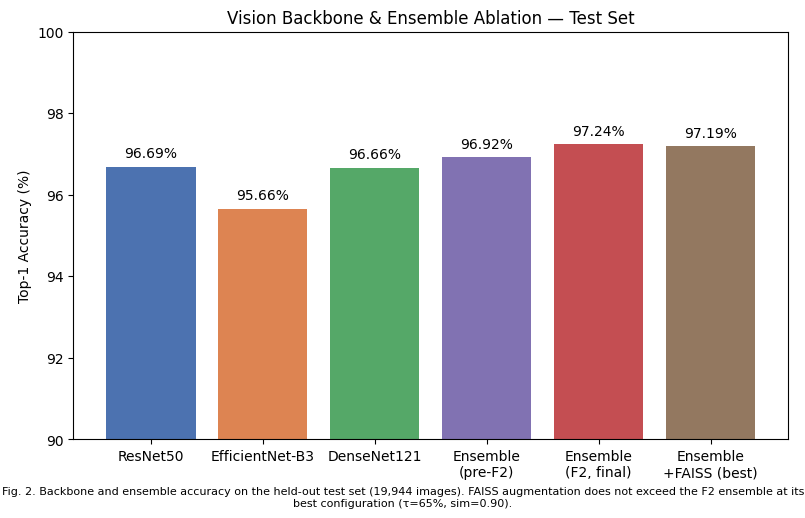

In [1]:
import matplotlib.pyplot as plt

labels = ["ResNet50", "EfficientNet-B3", "DenseNet121", "Ensemble\n(pre-F2)", "Ensemble\n(F2, final)", "Ensemble\n+FAISS (best)"]
accuracies = [96.6857, 95.6629, 96.6606, 96.92, 97.2423, 97.1871]
colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2", "#C44E52", "#937860"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, accuracies, color=colors)

for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            f"{acc:.2f}%", ha="center", va="bottom", fontsize=10)

ax.set_ylabel("Top-1 Accuracy (%)")
ax.set_ylim(90, 100)
ax.set_title("Vision Backbone & Ensemble Ablation — Test Set")
plt.figtext(0.5, -0.02,
            "Fig. 2. Backbone and ensemble accuracy on the held-out test set (19,944 images). "
            "FAISS augmentation does not exceed the F2 ensemble at its best configuration (τ=65%, sim=0.90).",
            wrap=True, ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("fig2_ablation.png", dpi=300, bbox_inches="tight")
plt.show()